# Paso 4B: Extracción Automatizada de Jugadas y Construcción del Dataset VLM
**Directorio:** `/to-verify/03-action-extraction-joaquin.ipynb` (Candidato a Producción)

Implementación modular de los 4 sub-sistemas definidos en `docs/action-extraction-spec.md`:
1. **Sub-sistema 1 (Detector Temporal):** Lectura sub-unidad de las 10 celdas de elixir ($\Delta E \le -1.5$), verificación de rotación estructural en mano y filtro de oclusión de chat.
2. **Sub-sistema 2 (Identificador de Carta):** Catálogo oficial automatizado (~110 cartas) + Inferencia restringida al Mazo Activo de 8 Cartas (*Deck-Constraint*) + Validación cruzada de coste de elixir.
3. **Sub-sistema 3 (Localizador Espacial en Arena):** Detección del despliegue en $[t_{\text{drop}} - 0.1\text{s}, t_{\text{drop}} + 0.3\text{s}]$ con supresión de movimiento previo y proyección sobre las 6 zonas estratégicas.
4. **Sub-sistema 4 (Ensamblador VLM y Subida a R2):** Prevención estricta de *Data Leakage* ($t_{\text{actual}} = t_{\text{drop}} - 0.65\text{s}$), balanceo 82% `play` / 18% `wait`, y persistencia atómica en Cloudflare R2.

In [3]:
import os
import json
import cv2
import boto3
import requests
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from botocore.config import Config
from dotenv import load_dotenv

# Carga automática del archivo .env desde la raíz del repositorio
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name in ["to-verify", "staging", "notebooks"] else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

def get_secret(key: str, default: str = None) -> str:
    val = os.getenv(key)
    if val:
        return val.strip()
    try:
        from kaggle_secrets import UserSecretsClient
        val = UserSecretsClient().get_secret(key)
        if val:
            return val.strip()
    except Exception:
        pass
    return default

# Directorios temporales (evita saturar disco según AGENTS.md)
WORK_DIR = Path("/kaggle/working/action_extraction") if Path("/kaggle").exists() else (PROJECT_ROOT / "data" / "temp_extraction")
CARD_BANK_DIR = WORK_DIR / "card_bank"
OUTPUT_DIR = WORK_DIR / "output"
for d in [WORK_DIR, CARD_BANK_DIR, OUTPUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

class R2StorageManager:
    """Cliente S3/R2 para lectura de manifiestos y subida de checkpoints."""
    def __init__(self):
        self.endpoint = get_secret("R2_ENDPOINT")
        self.access_key = get_secret("R2_ACCESS_KEY")
        self.secret_key = get_secret("R2_SECRET_KEY")
        self.bucket = get_secret("R2_BUCKET", "cr-videos")
        self.cdn_url = get_secret("CDN_URL", "https://cdn-cr.eddux.dev").rstrip("/")

        if not all([self.endpoint, self.access_key, self.secret_key]):
            raise RuntimeError(f"Faltan credenciales R2 en {PROJECT_ROOT / '.env'}")

        self.s3 = boto3.client(
            "s3",
            endpoint_url=self.endpoint,
            aws_access_key_id=self.access_key,
            aws_secret_access_key=self.secret_key,
            config=Config(signature_version="s3v4", retries={"max_attempts": 3})
        )

    def read_json(self, key: str) -> dict:
        resp = self.s3.get_object(Bucket=self.bucket, Key=key)
        try:
            return json.loads(resp["Body"].read().decode("utf-8"))
        finally:
            resp["Body"].close()

    def key_exists(self, key: str) -> bool:
        try:
            self.s3.head_object(Bucket=self.bucket, Key=key)
            return True
        except Exception:
            return False

    def download_video(self, video_id: str) -> Path:
        target = WORK_DIR / f"{video_id}.mp4"
        if target.exists():
            return target
        part = target.with_suffix(".mp4.part")
        url = f"{self.cdn_url}/videos/{video_id}.mp4"
        print(f"Descargando video {video_id} desde CDN...")
        with requests.get(url, stream=True, timeout=(15, 180)) as r:
            r.raise_for_status()
            with open(part, "wb") as f:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
        part.replace(target)
        return target

    def upload_file(self, local_path: Path, r2_key: str):
        self.s3.upload_file(str(local_path), self.bucket, r2_key)

class MatchStreamBuffer:
    """
    Buffer ultra-ligero en RAM:
    1. Garantiza cap.release() con try/finally para evitar [WinError 32] en Windows.
    2. Codifica los frames en memoria en JPEG de alta calidad (reduce el uso de RAM de ~10 GB a ~350 MB).
    """
    def __init__(self, video_path: Path, start_sec: float, end_sec: float, scan_fps: float = 10.0):
        self.video_path = video_path
        self.start_sec = float(start_sec)
        self.end_sec = float(end_sec)
        self.scan_fps = float(scan_fps)
        self.dt = 1.0 / self.scan_fps
        self.timestamps = []
        self._compressed_frames = []
        self._decode_stream()

    def _decode_stream(self):
        cap = cv2.VideoCapture(str(self.video_path))
        if not cap.isOpened():
            raise RuntimeError(f"Error al abrir MP4: {self.video_path}")
        
        try:
            src_fps = float(cap.get(cv2.CAP_PROP_FPS))
            start_f = int(round(self.start_sec * src_fps))
            end_f = int(round(self.end_sec * src_fps))
            cap.set(cv2.CAP_PROP_POS_FRAMES, start_f)
            curr_f = start_f
            next_t = self.start_sec

            encode_params = [int(cv2.IMWRITE_JPEG_QUALITY), 95]
            while curr_f <= end_f:
                ok, bgr = cap.read()
                if not ok or bgr is None:
                    break
                t_now = curr_f / src_fps
                if t_now >= next_t - (0.5 / src_fps):
                    # Guardar comprimido en memoria RAM (ahorra 95% de RAM en videos 1080p)
                    ok_enc, buf = cv2.imencode(".jpg", bgr, encode_params)
                    if ok_enc:
                        self.timestamps.append(round(t_now, 2))
                        self._compressed_frames.append(buf)
                    next_t += self.dt
                curr_f += 1
        finally:
            # SIEMPRE libera el archivo en Windows aunque ocurra una excepción
            cap.release()

        self.timestamps = np.array(self.timestamps)
        ram_mb = sum(b.nbytes for b in self._compressed_frames) / (1024 * 1024)
        print(f"Buffer listo: {len(self._compressed_frames)} frames ({ram_mb:.1f} MB en RAM).")

    def _decode_idx(self, idx: int) -> np.ndarray:
        bgr = cv2.imdecode(self._compressed_frames[idx], cv2.IMREAD_COLOR)
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    @property
    def frames(self):
        """Generador perezoso (lazy) para no descomprimir todos los frames al mismo tiempo."""
        for i in range(len(self._compressed_frames)):
            yield self._decode_idx(i)

    def __len__(self):
        return len(self._compressed_frames)

    def get_frame(self, t_sec: float) -> np.ndarray:
        idx = int(np.argmin(np.abs(self.timestamps - t_sec)))
        return self._decode_idx(idx)

    def clear(self):
        self._compressed_frames.clear()
        self.timestamps = np.array([])
        gc.collect()

def crop_roi(frame: np.ndarray, box: list) -> np.ndarray:
    x, y, w, h = map(int, box)
    return frame[y:y+h, x:x+w]

storage = R2StorageManager()
segments_manifest = storage.read_json("metadata/segmented_matches.json")["videos"]
layouts_manifest = storage.read_json("metadata/ui_layouts.json")["layouts"]
print(f"Conectado a R2: {len(segments_manifest)} videos segmentados | {len(layouts_manifest)} layouts calibrados.")

Conectado a R2: 52 videos segmentados | 52 layouts calibrados.


In [4]:
class SubSystem1_TemporalDetector:
    """Sub-sistema 1: Detector Temporal de Eventos (t_drop) con filtrado de casos borde."""
    def __init__(self, layout: dict, scan_fps: float = 10.0):
        self.boxes = layout["boxes_pixel"]
        self.scan_fps = scan_fps

    def measure_elixir(self, frame_rgb: np.ndarray) -> float:
        bar = crop_roi(frame_rgb, self.boxes["elixir_bar_box"])
        h, w, _ = bar.shape
        cells_strip = bar[int(h * 0.42):int(h * 0.78), int(w * 0.115):int(w * 0.985)]
        hsv = cv2.cvtColor(cells_strip, cv2.COLOR_RGB2HSV)
        mask = (
            ((hsv[:, :, 0] >= 132) & (hsv[:, :, 0] <= 175)) &
            (hsv[:, :, 1] >= 70) &
            (hsv[:, :, 2] >= 85)
        )
        col_bin = (mask.mean(axis=0) > 0.40).astype(np.uint8)
        col_smooth = cv2.medianBlur(col_bin.reshape(1, -1), 5).flatten()
        filled = np.where(col_smooth > 0)[0]
        if len(filled) == 0:
            return 0.0
        elixir = ((filled[-1] + 1) / len(col_smooth)) * 10.0
        return round(float(np.clip(elixir, 0.0, 10.0)), 2)

    def is_chat_open(self, slot_crops: list) -> bool:
        blue_count = 0
        for sc in slot_crops:
            hsv = cv2.cvtColor(sc, cv2.COLOR_RGB2HSV)
            if np.mean((hsv[:, :, 0] >= 95) & (hsv[:, :, 0] <= 128) & (hsv[:, :, 1] >= 85)) > 0.50:
                blue_count += 1
        return blue_count >= 3

    def analyze_stream(self, buffer: MatchStreamBuffer):
        rows = []
        for idx, (t_sec, frame) in enumerate(zip(buffer.timestamps, buffer.frames)):
            elx = self.measure_elixir(frame)
            slots = [crop_roi(frame, b) for b in self.boxes["card_slots"]]
            chat_occ = self.is_chat_open(slots)
            rows.append({"idx": idx, "t_sec": t_sec, "elixir": elx, "chat_occluded": chat_occ})
        
        df = pd.DataFrame(rows)
        df["elixir_smooth"] = df["elixir"].rolling(window=3, center=True, min_periods=1).median()
        
        events = []
        win = int(round(0.5 * self.scan_fps))
        cooldown = int(round(0.7 * self.scan_fps))
        elx_arr = df["elixir_smooth"].values
        t_arr = df["t_sec"].values
        chat_arr = df["chat_occluded"].values
        
        last_idx = -cooldown
        margin = int(1.2 * self.scan_fps)

        for i in range(margin, len(df) - margin):
            if i - last_idx < cooldown or chat_arr[i]:
                continue
            e_peak = np.max(elx_arr[i - win : i + 1])
            e_valley = np.min(elx_arr[i : i + win + 1])
            delta_e = e_valley - e_peak

            if delta_e <= -1.5 and (elx_arr[i - 1] - elx_arr[i + 1]) >= 0.75:
                t_drop = float(t_arr[i])
                f_pre = buffer.get_frame(t_drop - 0.8)
                f_post = buffer.get_frame(t_drop + 1.0)
                
                slot_diffs = []
                for s in range(4):
                    sb = self.boxes["card_slots"][s]
                    c1 = crop_roi(f_pre, sb)
                    c2 = crop_roi(f_post, sb)
                    sh, sw, _ = c1.shape
                    g1 = cv2.cvtColor(c1[int(sh*0.22):int(sh*0.78), int(sw*0.18):int(sw*0.82)], cv2.COLOR_RGB2GRAY)
                    g2 = cv2.cvtColor(c2[int(sh*0.22):int(sh*0.78), int(sw*0.18):int(sw*0.82)], cv2.COLOR_RGB2GRAY)
                    slot_diffs.append(float(np.mean(cv2.absdiff(g1, g2))))

                best_slot = int(np.argmax(slot_diffs))
                if slot_diffs[best_slot] > 20.0:
                    events.append({
                        "frame_idx": i,
                        "t_drop": round(t_drop, 2),
                        "delta_elixir": round(float(delta_e), 2),
                        "estimated_cost": int(np.clip(round(abs(delta_e)), 1, 9)),
                        "hand_slot": best_slot,
                        "slot_diff_score": round(slot_diffs[best_slot], 2)
                    })
                    last_idx = i
        return df, events

In [5]:
class SubSystem2_CardIdentifier:
    """Sub-sistema 2: Clasificador de Cartas con Restricción de Mazo de 8 Cartas."""
    META_URL = "https://royaleapi.github.io/cr-api-data/json/cards.json"
    IMG_BASE = "https://cdns3.royaleapi.com/cdn-cgi/image/w=150,f=auto/static/img/cards-150"

    ES_TRANSLATION = {
        "Hog Rider": "Montapuercos", "Musketeer": "Mosquetera", "Ice Golem": "Gólem de Hielo",
        "Ice Spirit": "Espíritu de Hielo", "Skeletons": "Esqueletos", "Cannon": "Cañón",
        "Fireball": "Bola de Fuego", "The Log": "El Tronco", "Valkyrie": "Valquiria",
        "Knight": "Caballero", "Archers": "Arqueras", "Goblin Barrel": "Barril de Duendes",
        "Princess": "Princesa", "Goblin Gang": "Pandilla de Duendes", "Inferno Tower": "Torre Infernal",
        "Rocket": "Cohete", "Electro Spirit": "Espíritu Eléctrico", "Fire Spirit": "Espíritu de Fuego",
        "Zap": "Descarga", "Arrows": "Flechas", "Tornado": "Tornado", "P.E.K.K.A": "P.E.K.K.A",
        "Mega Knight": "Megacaballero", "Mini P.E.K.K.A": "Mini P.E.K.K.A", "Bandit": "Bandida",
        "Royal Ghost": "Fantasma Real", "Battle Ram": "Ariete de Batalla", "Magic Archer": "Arquero Mágico",
        "Electro Wizard": "Mago Eléctrico", "Miner": "Minero", "Poison": "Veneno",
        "Wall Breakers": "Rompemuros", "Bomb Tower": "Torre Bombardera", "Bats": "Murciélagos",
        "Spear Goblins": "Duendes con Lanza", "Goblins": "Duendes", "Royal Giant": "Gigante Real",
        "Fisherman": "Pescador", "Hunter": "Cazador", "Lightning": "Rayo", "Golem": "Gólem",
        "Baby Dragon": "Bebé Dragón", "Night Witch": "Bruja Nocturna", "Lumberjack": "Leñador",
        "Balloon": "Globo Bombástico", "Freeze": "Hielo", "Bowler": "Lanzarrocas",
        "Executioner": "Verdugo", "Graveyard": "Cementerio", "Tesla": "Torre Tesla",
        "X-Bow": "Ballesta", "Mortar": "Mortero", "Royal Hogs": "Puercos Reales",
        "Royal Delivery": "Paquete Real", "Earthquake": "Terremoto", "Firecracker": "Lanzafuegos",
        "Mighty Miner": "Gran Minero", "Golden Knight": "Caballero Dorado", "Skeleton King": "Rey Esqueleto",
        "Archer Queen": "Reina Arquera", "Monk": "Monje", "Little Prince": "Principito",
        "Giant": "Gigante", "Witch": "Bruja", "Wizard": "Mago", "Minions": "Esbirros",
        "Minion Horde": "Horda de Esbirros", "Sparky": "Chispitas", "Elite Barbarians": "Bárbaros de Élite",
        "Barbarians": "Bárbaros", "Barbarian Barrel": "Barril de Bárbaro", "Dark Prince": "Príncipe Oscuro",
        "Prince": "Príncipe", "Guards": "Guardias", "Tombstone": "Lápida", "Furnace": "Horno",
        "Goblin Drill": "Excavadora de Duendes", "Electro Giant": "Gigante Eléctrico", "Phoenix": "Fénix"
    }

    def __init__(self, bank_dir: Path):
        self.bank_dir = bank_dir
        self.catalog = {}
        self._load_or_fetch_catalog()

    def _load_or_fetch_catalog(self):
        meta_path = self.bank_dir / "cards_meta.json"
        if not meta_path.exists():
            print("Descargando catálogo oficial de cartas de Clash Royale...")
            r = requests.get(self.META_URL, timeout=30)
            r.raise_for_status()
            meta_path.write_text(r.text, encoding="utf-8")

        cards = json.loads(meta_path.read_text(encoding="utf-8"))
        for c in cards:
            key = c.get("key")
            name_en = c.get("name")
            elixir = c.get("elixir")
            if not key or elixir is None:
                continue
            img_file = self.bank_dir / f"{key}.png"
            if not img_file.exists():
                try:
                    res = requests.get(f"{self.IMG_BASE}/{key}.png", timeout=10)
                    if res.status_code == 200:
                        img_file.write_bytes(res.content)
                except Exception:
                    continue
            if img_file.exists():
                bgr = cv2.imread(str(img_file))
                if bgr is not None:
                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                    h, w, _ = rgb.shape
                    core = cv2.resize(rgb[int(h*0.18):int(h*0.82), int(w*0.14):int(w*0.86)], (64, 76))
                    self.catalog[key] = {
                        "key": key,
                        "name_es": self.ES_TRANSLATION.get(name_en, name_en),
                        "elixir": int(elixir),
                        "lab": cv2.cvtColor(core, cv2.COLOR_RGB2LAB),
                        "gray": cv2.cvtColor(core, cv2.COLOR_RGB2GRAY)
                    }
        print(f"Banco Canónico listo con {len(self.catalog)} cartas oficiales.")

    def _match_score(self, slot_rgb: np.ndarray, card_info: dict) -> float:
        slot_std = cv2.resize(slot_rgb, (90, 110))
        slot_lab = cv2.cvtColor(slot_std, cv2.COLOR_RGB2LAB)
        slot_gray = cv2.cvtColor(slot_std, cv2.COLOR_RGB2GRAY)
        rg = cv2.matchTemplate(slot_gray, card_info["gray"], cv2.TM_CCOEFF_NORMED)
        ra = cv2.matchTemplate(slot_lab[:, :, 1], card_info["lab"][:, :, 1], cv2.TM_CCOEFF_NORMED)
        rb = cv2.matchTemplate(slot_lab[:, :, 2], card_info["lab"][:, :, 2], cv2.TM_CCOEFF_NORMED)
        return float(np.max(0.45 * rg + 0.275 * ra + 0.275 * rb))

    def identify_events_with_deck_constraint(self, events: list, buffer: MatchStreamBuffer, layout: dict):
        slot_boxes = layout["boxes_pixel"]["card_slots"]
        deck_scores = {}

        sample_times = np.linspace(buffer.start_sec + 5.0, buffer.end_sec - 5.0, min(25, len(buffer)))
        for t in sample_times:
            frame = buffer.get_frame(t)
            for sb in slot_boxes:
                sc = crop_roi(frame, sb)
                best_k, best_val = None, -1.0
                for k, info in self.catalog.items():
                    val = self._match_score(sc, info)
                    if val > best_val:
                        best_val = val
                        best_k = k
                if best_k and best_val > 0.48:
                    deck_scores[best_k] = deck_scores.get(best_k, 0.0) + best_val

        top8_keys = sorted(deck_scores, key=deck_scores.get, reverse=True)[:8]
        active_deck = {k: self.catalog[k] for k in top8_keys} if len(top8_keys) >= 6 else self.catalog
        deck_names = [self.catalog[k]["name_es"] for k in top8_keys]

        for ev in events:
            f_pre = buffer.get_frame(ev["t_drop"] - 0.8)
            slot_img = crop_roi(f_pre, slot_boxes[ev["hand_slot"]])
            best_card, best_total = None, -1.0
            for k, info in active_deck.items():
                cost_diff = abs(info["elixir"] - ev["estimated_cost"])
                penalty = 0.0 if cost_diff <= 1 else 0.25 * cost_diff
                score = self._match_score(slot_img, info) - penalty
                if score > best_total:
                    best_total = score
                    best_card = info

            ev["card_name"] = best_card["name_es"]
            ev["elixir_cost"] = best_card["elixir"]
            ev["card_conf"] = round(best_total, 3)

        return deck_names, events

card_classifier = SubSystem2_CardIdentifier(CARD_BANK_DIR)

Banco Canónico listo con 120 cartas oficiales.


In [6]:
class SubSystem3_ArenaLocator:
    """Sub-sistema 3: Localizador espacial con supresión de movimiento previo y mapeo a 6 zonas."""
    ZONES = {
        1: "detrás del puente izquierdo",
        2: "detrás del puente derecho",
        3: "frente a la torre izquierda",
        4: "frente a la torre derecha",
        5: "en el centro del campo propio",
        6: "detrás de la torre del rey"
    }

    @classmethod
    def locate(cls, buffer: MatchStreamBuffer, arena_box: list, t_drop: float):
        a_prev2 = crop_roi(buffer.get_frame(t_drop - 0.4), arena_box)
        a_prev1 = crop_roi(buffer.get_frame(t_drop - 0.1), arena_box)
        a_post1 = crop_roi(buffer.get_frame(t_drop + 0.3), arena_box)

        g0 = cv2.GaussianBlur(cv2.cvtColor(a_prev2, cv2.COLOR_RGB2GRAY), (5, 5), 0)
        g1 = cv2.GaussianBlur(cv2.cvtColor(a_prev1, cv2.COLOR_RGB2GRAY), (5, 5), 0)
        g2 = cv2.GaussianBlur(cv2.cvtColor(a_post1, cv2.COLOR_RGB2GRAY), (5, 5), 0)

        prev_motion = cv2.dilate(cv2.absdiff(g1, g0), np.ones((9, 9), np.uint8), iterations=1)
        spawn_motion = cv2.absdiff(g2, g1)
        clean_diff = cv2.subtract(spawn_motion, cv2.multiply(prev_motion, 1.25).astype(np.uint8))

        h, w = clean_diff.shape
        own_mask = np.zeros_like(clean_diff)
        own_mask[int(h * 0.44):int(h * 0.96), int(w * 0.04):int(w * 0.96)] = 255
        masked = cv2.bitwise_and(clean_diff, own_mask)

        _, thresh = cv2.threshold(masked, 25, 255, cv2.THRESH_BINARY)
        closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)), iterations=2)

        contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        valid = [c for c in contours if cv2.contourArea(c) >= 30]

        if valid:
            best_c = max(valid, key=cv2.contourArea)
            M = cv2.moments(best_c)
            cx = M["m10"] / max(M["m00"], 1e-5)
            cy = M["m01"] / max(M["m00"], 1e-5)
            nx, ny = round(float(cx / w), 3), round(float(cy / h), 3)
        else:
            nx, ny = 0.500, 0.700

        zid, zname = cls.coord_to_zone(nx, ny)
        return [nx, ny], zid, zname

    @classmethod
    def coord_to_zone(cls, nx: float, ny: float):
        if ny < 0.61:
            return (1, cls.ZONES[1]) if nx < 0.5 else (2, cls.ZONES[2])
        elif ny > 0.81:
            return (6, cls.ZONES[6])
        else:
            if 0.36 <= nx <= 0.64:
                return (5, cls.ZONES[5])
            elif nx < 0.36:
                return (3, cls.ZONES[3])
            else:
                return (4, cls.ZONES[4])

class SubSystem4_DatasetAssembler:
    """Sub-sistema 4: Muestreo de 'esperar' y ensamblador de muestras VLM sin Data Leakage."""
    @staticmethod
    def sample_passive_waits(start_sec: float, end_sec: float, play_times: list, n_plays: int) -> list:
        n_waits = max(1, int(round(n_plays * (0.18 / 0.82))))
        candidates = np.arange(start_sec + 8.0, end_sec - 2.0, 2.0)
        safe_waits = [round(float(t), 2) for t in candidates if all(abs(t - tp) >= 3.2 for tp in play_times)]
        if len(safe_waits) > n_waits:
            idx = np.linspace(0, len(safe_waits) - 1, n_waits, dtype=int)
            safe_waits = [safe_waits[i] for i in idx]
        return safe_waits

    @staticmethod
    def export_match_samples(video_id: str, match_index: int, events: list, wait_times: list,
                             buffer: MatchStreamBuffer, out_dir: Path, r2: R2StorageManager = None,
                             upload_to_r2: bool = False) -> list:
        samples_dir = out_dir / "samples"
        samples_dir.mkdir(parents=True, exist_ok=True)
        jsonl_records = []

        for idx, ev in enumerate(events, start=1):
            t_actual = round(ev["t_drop"] - 0.65, 2)
            if t_actual - 6.0 < buffer.start_sec:
                continue
            sample_id = f"{video_id}_m{match_index}_play_{idx:03d}"
            frame_rels = []
            for off in [-6, -4, -2, 0]:
                rel_p = f"samples/{sample_id}_t{off}s.jpg"
                local_p = out_dir / rel_p
                rgb = buffer.get_frame(t_actual + off)
                cv2.imwrite(str(local_p), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 92])
                frame_rels.append(rel_p)
                if upload_to_r2 and r2:
                    r2.upload_file(local_p, rel_p)

            z_clean = ev["placement_zone"]
            jsonl_records.append({
                "sample_id": sample_id,
                "video_id": video_id,
                "match_index": match_index,
                "timestamp_sec": t_actual,
                "frames": frame_rels,
                "action_type": "play",
                "card_name": ev["card_name"],
                "elixir_cost": ev["elixir_cost"],
                "hand_slot": ev["hand_slot"],
                "placement_coord": ev["placement_coord"],
                "placement_zone": z_clean.capitalize() + ".",
                "target_text": f"Juega {ev['card_name']} {z_clean}."
            })

        for idx, t_wait in enumerate(wait_times, start=1):
            if t_wait - 6.0 < buffer.start_sec:
                continue
            sample_id = f"{video_id}_m{match_index}_wait_{idx:03d}"
            frame_rels = []
            for off in [-6, -4, -2, 0]:
                rel_p = f"samples/{sample_id}_t{off}s.jpg"
                local_p = out_dir / rel_p
                rgb = buffer.get_frame(t_wait + off)
                cv2.imwrite(str(local_p), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 92])
                frame_rels.append(rel_p)
                if upload_to_r2 and r2:
                    r2.upload_file(local_p, rel_p)

            jsonl_records.append({
                "sample_id": sample_id,
                "video_id": video_id,
                "match_index": match_index,
                "timestamp_sec": t_wait,
                "frames": frame_rels,
                "action_type": "wait",
                "card_name": None,
                "elixir_cost": None,
                "hand_slot": None,
                "placement_coord": None,
                "placement_zone": None,
                "target_text": "esperar"
            })
        return jsonl_records

Descargando video 4Tt7nuuy-Bg desde CDN...
Buffer listo: 1791 frames (114.0s - 293.0s a 10.0 FPS).

Mazo de 8 cartas detectado: ['El Tronco', 'Cohete', 'Príncipe Oscuro', 'Torre Infernal', 'Princesa', 'Barril de Duendes', 'Dart Goblin', 'Skeleton Barrel']
Jugadas extraídas en piloto: 24


,frame_idx,t_drop,delta_elixir,estimated_cost,hand_slot,slot_diff_score,card_name,elixir_cost,card_conf,placement_coord,zone_id,placement_zone
0,80,122.00,-2.06,2,1,31.44,Skeleton Barrel,3,0.178,"[0.821, 0.55]",2,detrás del puente derecho
1,93,123.29,-2.57,3,2,105.35,Skeleton Barrel,3,0.405,"[0.552, 0.609]",2,detrás del puente derecho
2,201,134.09,-2.57,3,2,88.72,Princesa,3,0.611,"[0.501, 0.475]",2,detrás del puente derecho
3,292,143.20,-4.29,4,3,150.06,Skeleton Barrel,3,0.430,"[0.426, 0.667]",5,en el centro del campo propio
4,337,147.71,-1.72,2,0,114.67,Skeleton Barrel,3,0.408,"[0.708, 0.622]",4,frente a la torre derecha
5,601,174.10,-2.56,3,3,90.39,Skeleton Barrel,3,0.615,"[0.486, 0.475]",1,detrás del puente izquierdo
6,612,175.20,-2.56,3,0,66.09,Barril de Duendes,3,0.705,"[0.927, 0.499]",2,detrás del puente derecho
7,634,177.39,-2.57,3,0,68.80,Princesa,3,0.600,"[0.655, 0.554]",2,detrás del puente derecho
8,759,189.90,-2.52,3,0,66.19,Princesa,3,0.592,"[0.73, 0.538]",2,detrás del puente derecho
9,942,208.20,-3.40,3,2,62.31,Príncipe Oscuro,4,0.454,"[0.501, 0.475]",2,detrás del puente derecho


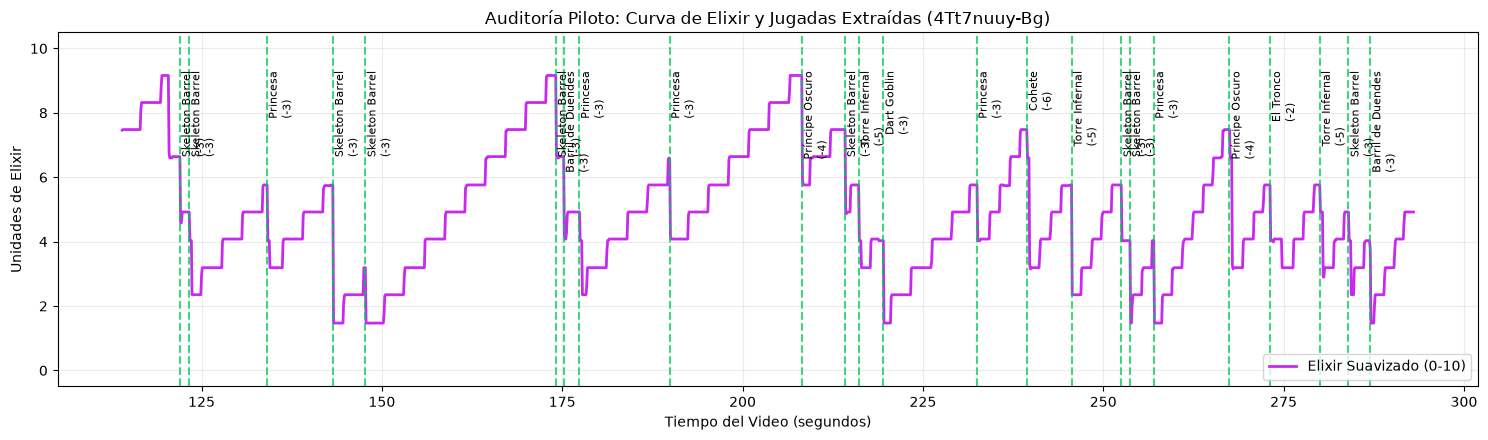

In [5]:
# Fases 1, 2 y 3: Prueba en 1 Video Piloto y Gráfica de Auditoría
PILOT_VIDEO_ID = next(v for v, info in segments_manifest.items() if v in layouts_manifest and info.get("matches"))
pilot_match = segments_manifest[PILOT_VIDEO_ID]["matches"][0]
pilot_layout = layouts_manifest[PILOT_VIDEO_ID]

video_file = storage.download_video(PILOT_VIDEO_ID)
stream_buf = MatchStreamBuffer(video_file, pilot_match["start_sec"], pilot_match["end_sec"], scan_fps=10.0)

detector = SubSystem1_TemporalDetector(pilot_layout, scan_fps=10.0)
timeline_df, detected_events = detector.analyze_stream(stream_buf)
detected_deck, detected_events = card_classifier.identify_events_with_deck_constraint(
    detected_events, stream_buf, pilot_layout
)

arena_box = pilot_layout["boxes_pixel"]["arena_box"]
for ev in detected_events:
    coord, zid, zname = SubSystem3_ArenaLocator.locate(stream_buf, arena_box, ev["t_drop"])
    ev["placement_coord"] = coord
    ev["zone_id"] = zid
    ev["placement_zone"] = zname

print(f"\nMazo de 8 cartas detectado: {detected_deck}")
print(f"Jugadas extraídas en piloto: {len(detected_events)}")
display(pd.DataFrame(detected_events))

plt.figure(figsize=(15, 4.5))
plt.plot(timeline_df["t_sec"], timeline_df["elixir_smooth"], label="Elixir Suavizado (0-10)", color="#c828f0", lw=2)
for ev in detected_events:
    plt.axvline(ev["t_drop"], color="#00c853", linestyle="--", alpha=0.75)
    plt.text(ev["t_drop"], 9.3, f"{ev['card_name']}\n(-{ev['elixir_cost']})", rotation=90, fontsize=8, va="top")
plt.title(f"Auditoría Piloto: Curva de Elixir y Jugadas Extraídas ({PILOT_VIDEO_ID})")
plt.xlabel("Tiempo del Video (segundos)")
plt.ylabel("Unidades de Elixir")
plt.ylim(-0.5, 10.5)
plt.grid(alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [7]:
# Fase 4: Exportación Masiva Optimizada en RAM y Segura en Windows
import gc
import time

UPLOAD_TO_R2 = False  # Cambiar a True cuando quieras subir a Cloudflare R2

# Liberar el buffer del video piloto de la Celda 5 si sigue ocupando RAM
if "stream_buf" in globals():
    try:
        del stream_buf
        gc.collect()
    except Exception:
        pass

actions_meta_dir = OUTPUT_DIR / "metadata" / "actions"
actions_meta_dir.mkdir(parents=True, exist_ok=True)

eligible_videos = [v for v, info in segments_manifest.items() if v in layouts_manifest and info.get("matches")]
print(f"Videos elegibles para procesamiento masivo: {len(eligible_videos)}")

for vid in eligible_videos:
    r2_jsonl_key = f"metadata/actions/{vid}.jsonl"
    local_jsonl = actions_meta_dir / f"{vid}.jsonl"

    # Si ya se procesó localmente o en R2, lo saltamos para no repetir trabajo
    if local_jsonl.exists() and local_jsonl.stat().st_size > 0:
        if not UPLOAD_TO_R2:
            print(f"[SKIP LOCAL] {vid} ya fue procesado ({local_jsonl.name}).")
            continue
        elif storage.key_exists(r2_jsonl_key):
            print(f"[SKIP R2] {vid} ya cuenta con checkpoint en R2.")
            continue

    print(f"\n=== Procesando video: {vid} ===")
    v_path = storage.download_video(vid)
    v_layout = layouts_manifest[vid]
    all_video_samples = []

    try:
        for m_info in segments_manifest[vid]["matches"]:
            m_idx = m_info["match_index"]
            buf = MatchStreamBuffer(v_path, m_info["start_sec"], m_info["end_sec"], scan_fps=10.0)
            try:
                det = SubSystem1_TemporalDetector(v_layout, scan_fps=10.0)
                _, evs = det.analyze_stream(buf)
                _, evs = card_classifier.identify_events_with_deck_constraint(evs, buf, v_layout)
                
                for ev in evs:
                    coord, zid, zname = SubSystem3_ArenaLocator.locate(buf, v_layout["boxes_pixel"]["arena_box"], ev["t_drop"])
                    ev["placement_coord"] = coord
                    ev["placement_zone"] = zname

                play_ts = [e["t_drop"] for e in evs]
                wait_ts = SubSystem4_DatasetAssembler.sample_passive_waits(
                    buf.start_sec, buf.end_sec, play_ts, len(evs)
                )

                samples = SubSystem4_DatasetAssembler.export_match_samples(
                    video_id=vid, match_index=m_idx, events=evs, wait_times=wait_ts,
                    buffer=buf, out_dir=OUTPUT_DIR, r2=storage, upload_to_r2=UPLOAD_TO_R2
                )
                all_video_samples.extend(samples)
            finally:
                # Liberar RAM inmediatamente después de cada partida individual
                buf.clear()
                del buf
                gc.collect()

        with open(local_jsonl, "w", encoding="utf-8") as f:
            for rec in all_video_samples:
                f.write(json.dumps(rec, ensure_ascii=False) + "\n")

        if UPLOAD_TO_R2:
            storage.upload_file(local_jsonl, r2_jsonl_key)
            print(f"[OK R2] Subido {r2_jsonl_key} ({len(all_video_samples)} muestras).")
        else:
            print(f"[OK LOCAL] Guardado {local_jsonl.name} ({len(all_video_samples)} muestras).")

    finally:
        gc.collect()
        if v_path.exists():
            try:
                v_path.unlink(missing_ok=True)
            except PermissionError:
                time.sleep(0.5)
                try:
                    v_path.unlink(missing_ok=True)
                except Exception:
                    pass

Videos elegibles para procesamiento masivo: 44

=== Procesando video: 0x_i2gihYn4 ===
Descargando video 0x_i2gihYn4 desde CDN...
Buffer listo: 1301 frames (593.1 MB en RAM).
Buffer listo: 1551 frames (706.4 MB en RAM).
Buffer listo: 2831 frames (1307.2 MB en RAM).
Buffer listo: 1761 frames (807.2 MB en RAM).
Buffer listo: 2331 frames (1091.1 MB en RAM).
Buffer listo: 1941 frames (891.9 MB en RAM).
Buffer listo: 1751 frames (807.4 MB en RAM).
Buffer listo: 2951 frames (1396.4 MB en RAM).


KeyboardInterrupt: 